# Morocco Electricity Consumption and Environmental Factors Analysis
**AnalystLab Africa – Experience Lab Internship, Week 5 – Track 1: Data Analytics**

Scope: exploratory analysis and visualisation (Tasks 1–6). The dashboard is intentionally **not** included and will be built separately.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px, plotly.graph_objects as go
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
DATA='data/powerconsumption_cleaned.csv'; DICT='data/powerconsumption_datadictionary.csv'
STATIC='charts/static'; INTER='charts/interactive'
os.makedirs(STATIC, exist_ok=True); os.makedirs(INTER, exist_ok=True)
ZONES=['PowerConsumption_Zone1','PowerConsumption_Zone2','PowerConsumption_Zone3']
ZN={'PowerConsumption_Zone1':'Zone 1','PowerConsumption_Zone2':'Zone 2','PowerConsumption_Zone3':'Zone 3'}
ENV=['Temperature','Humidity','WindSpeed']
DAYS=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
MONTHS=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
R={}   # key results, saved to results.json for the report
def save(fig,name):
    fig.savefig(f'{STATIC}/{name}.png', dpi=150, bbox_inches='tight'); plt.show()

## Task 1 – Dataset understanding and inspection

In [2]:
df = pd.read_csv(DATA)
dd = pd.read_csv(DICT, encoding='utf-8-sig')
print('Shape:', df.shape); print('Columns:', list(df.columns))
display(df.head()); display(dd); df.info()

Shape: (52416, 15)
Columns: ['Datetime', 'Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3', 'Year', 'Month', 'Day', 'Hour', 'DayOfWeek', 'Date']


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,Year,Month,Day,Hour,DayOfWeek,Date
0,2017-01-01 00:00:00,6.56,73.80,0.08,0.05,0.12,"34,055.70","16,128.88","20,240.96",2017,1,1,0,Sunday,2017-01-01
1,2017-01-01 00:10:00,6.41,74.50,0.08,0.07,0.09,"29,814.68","19,375.08","20,131.08",2017,1,1,0,Sunday,2017-01-01
2,2017-01-01 00:20:00,6.31,74.50,0.08,0.06,0.10,"29,128.10","19,006.69","19,668.43",2017,1,1,0,Sunday,2017-01-01
3,2017-01-01 00:30:00,6.12,75.00,0.08,0.09,0.10,"28,228.86","18,361.09","18,899.28",2017,1,1,0,Sunday,2017-01-01
4,2017-01-01 00:40:00,5.92,75.70,0.08,0.05,0.09,"27,335.70","17,872.34","18,442.41",2017,1,1,0,Sunday,2017-01-01


,Field,Description
0,Datetime,The date and time of the recording
1,Temperature,The Temperature in Celsius
2,Humidity,The concentration of water vapor in the air
3,WindSpeed,The speed of the wind in kilometers per hour
4,GeneralDiffuseFlows,The measurement of how much emissions gases di...
5,DiffuseFlows,The measurement of how much emissions gases di...
6,PowerConsumption_Zone1,The power consumption in Kilowatt-Hours in Pow...
7,PowerConsumption_Zone2,The power consumption in Kilowatt-Hours in Pow...
8,PowerConsumption_Zone3,The power consumption in Kilowatt-Hours in Pow...


<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  str    
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
 9   Year                    52416 non-null  int64  
 10  Month                   52416 non-null  int64  
 11  Day                     52416 non-null  int64  
 12  Hour                    52416 non-null  int64  
 13  DayOfWeek               52416 non-null  str    
 14  Date                    52416 non-null  str    
d

In [3]:
# Missing values, duplicates, date-time conversion, interval consistency
df['Datetime'] = pd.to_datetime(df['Datetime'])
print('Missing values per column:\n', df.isna().sum().to_string())
print('\nDuplicate rows:', df.duplicated().sum(), '| duplicate timestamps:', df['Datetime'].duplicated().sum())
print('Sorted chronologically:', df['Datetime'].is_monotonic_increasing)
gaps = df['Datetime'].diff().dropna().value_counts()
print('\nTime gaps between consecutive rows:\n', gaps.to_string())
print('\nPeriod:', df['Datetime'].min(), '->', df['Datetime'].max())
per_day = df.groupby(df['Datetime'].dt.date).size()
print('Days covered:', per_day.size, '| days with != 144 readings:', int((per_day!=144).sum()))
print('Expected rows (364 days x 144):', 364*144, '| actual:', len(df))
R['rows']=len(df); R['start']=str(df.Datetime.min()); R['end']=str(df.Datetime.max())
R['missing']=int(df.isna().sum().sum()); R['dup']=int(df.duplicated().sum()); R['gap_ok']=bool(len(gaps)==1)

Missing values per column:
 Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
Year                      0
Month                     0
Day                       0
Hour                      0
DayOfWeek                 0
Date                      0

Duplicate rows: 0 | duplicate timestamps: 0
Sorted chronologically: True

Time gaps between consecutive rows:
 Datetime
0 days 00:10:00    52415

Period: 2017-01-01 00:00:00 -> 2017-12-30 23:50:00
Days covered: 364 | days with != 144 readings: 0
Expected rows (364 days x 144): 52416 | actual: 52416


### Interpreting the fields before analysis (as the brief requires)

**1. Unit of the consumption columns.** The dictionary labels the zones as kilowatt-hours, but the brief warns not to treat each 10-minute value as energy used in that interval. The check below tests both readings against the size of the numbers.

In [4]:
means = df[ZONES].mean(); total_mean_kw = means.sum()
as_kwh_per_interval = df[ZONES].sum().sum()          # if every reading were kWh used in 10 min
as_kw_power        = df[ZONES].sum().sum()/6         # if every reading is average kW over 10 min
print(f'Mean reading, all zones combined: {total_mean_kw:,.0f}')
print(f'Annual energy if values are kWh per 10-min : {as_kwh_per_interval/1e9:,.2f} TWh')
print(f'Annual energy if values are kW (x 1/6 hour): {as_kw_power/1e6:,.0f} GWh')
print(f'Implied average demand if kWh per 10 min   : {total_mean_kw*6/1000:,.0f} MW')
print(f'Implied average demand if kW               : {total_mean_kw/1000:,.0f} MW')
R['gwh_kw']=as_kw_power/1e6; R['twh_kwh']=as_kwh_per_interval/1e9; R['avg_mw']=total_mean_kw/1000

Mean reading, all zones combined: 71,223
Annual energy if values are kWh per 10-min : 3.73 TWh
Annual energy if values are kW (x 1/6 hour): 622 GWh
Implied average demand if kWh per 10 min   : 427 MW
Implied average demand if kW               : 71 MW


**Decision:** the readings are treated as **average power demand in kW for each 10-minute interval**. If they were energy per interval, three zones of one region would use about 3.7 TWh in a year (an implied average demand above 400 MW), which is implausibly large for this setting. As power, the total is about 0.62 TWh (about 71 MW average), which is realistic. Therefore:

- averages, peaks and comparisons use the readings directly (in kW);
- energy is only obtained as **kW × (10/60) h** per interval, never by summing raw readings;
- this is flagged as an assumption: the dictionary says kWh, so the programme team should confirm the unit.

**2. GeneralDiffuseFlows and DiffuseFlows.** The dictionary calls them gas-emission diffusion measures. The data behave differently, as tested below.

Mean at night (22:00-04:59):
 GeneralDiffuseFlows   0.06
DiffuseFlows          0.12

Peak hour of day: {'GeneralDiffuseFlows': 12, 'DiffuseFlows': 16} | peak mean values: {'GeneralDiffuseFlows': 589.0, 'DiffuseFlows': 182.0}


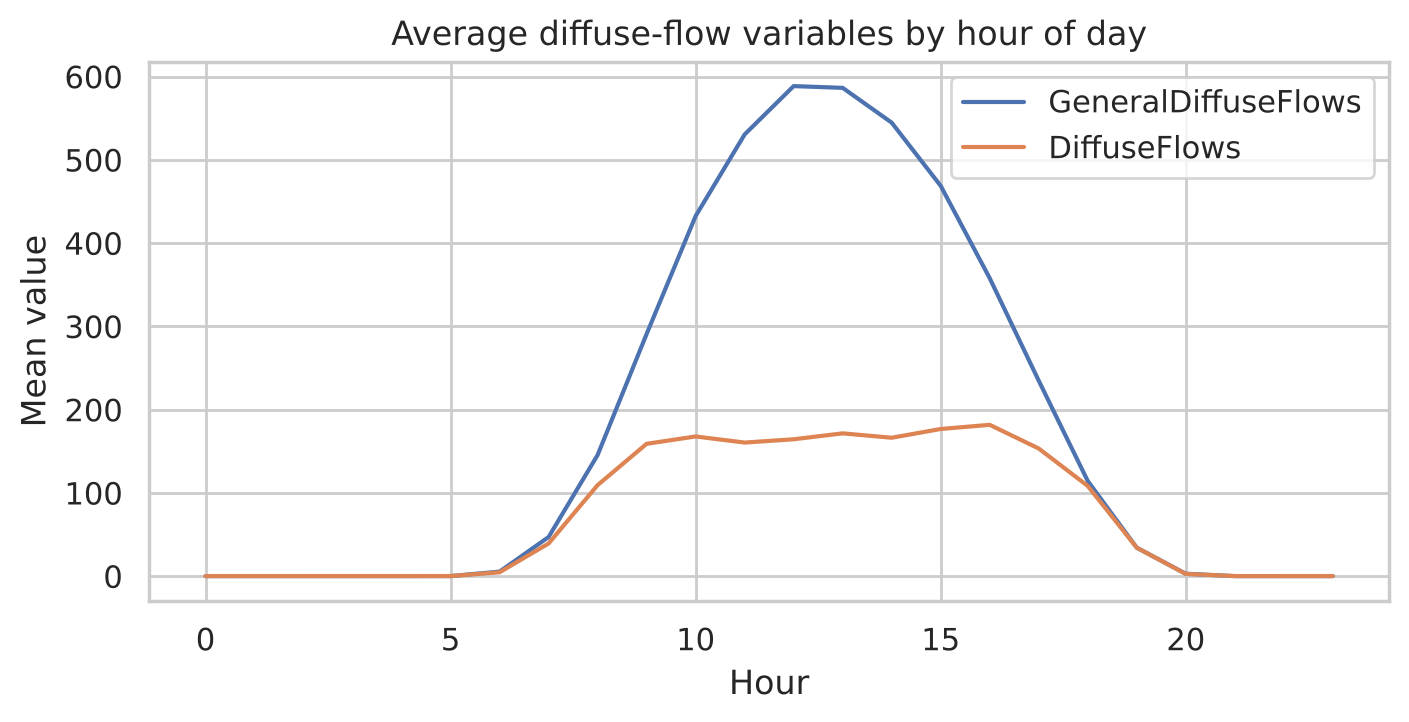

In [5]:
h = df.assign(Hour=df['Datetime'].dt.hour).groupby('Hour')[['GeneralDiffuseFlows','DiffuseFlows']].mean()
night = df[df['Datetime'].dt.hour.isin([22,23,0,1,2,3,4])][['GeneralDiffuseFlows','DiffuseFlows']].mean()
print('Mean at night (22:00-04:59):\n', night.round(2).to_string())
print('\nPeak hour of day:', h.idxmax().to_dict(), '| peak mean values:', h.max().round(0).to_dict())
fig,ax=plt.subplots(figsize=(8,3.5)); h.plot(ax=ax); ax.set_title('Average diffuse-flow variables by hour of day'); ax.set_ylabel('Mean value'); plt.show()

Both variables are about zero at night, rise after sunrise, peak around midday and fall after sunset. This is the signature of **solar radiation** (a global and a diffuse irradiance measure, plausibly W/m²), not of gas emissions. They are therefore described as *solar-radiation-like proxies* and used only as supporting context. **The dictionary description is unreliable and should be confirmed with the data owner.**

### Data-quality summary

In [6]:
display(Markdown(f'''
- **Size:** {len(df):,} rows, 9 original columns (+6 date columns already added in the cleaned file).
- **Missing values:** {R['missing']}. **Duplicate rows / timestamps:** {R['dup']}.
- **Intervals:** every gap is exactly 10 minutes: {R['gap_ok']}. The series is complete from {R['start']} to {R['end']}.
- **Coverage:** 31 December 2017 is absent (the brief states 1 Jan to 30 Dec), so the year has 364 days, and month totals differ in length.
- **Unit ambiguity:** dictionary says kWh; magnitudes indicate kW (see above).
- **Variable ambiguity:** diffuse-flow variables behave like solar radiation, not gas emissions.
- **Extreme values:** investigated in Task 2.
'''))


- **Size:** 52,416 rows, 9 original columns (+6 date columns already added in the cleaned file).
- **Missing values:** 0. **Duplicate rows / timestamps:** 0.
- **Intervals:** every gap is exactly 10 minutes: True. The series is complete from 2017-01-01 00:00:00 to 2017-12-30 23:50:00.
- **Coverage:** 31 December 2017 is absent (the brief states 1 Jan to 30 Dec), so the year has 364 days, and month totals differ in length.
- **Unit ambiguity:** dictionary says kWh; magnitudes indicate kW (see above).
- **Variable ambiguity:** diffuse-flow variables behave like solar radiation, not gas emissions.
- **Extreme values:** investigated in Task 2.


## Task 2 – Data cleaning and preparation

In [7]:
# Missing values / duplicates: none, so no imputation or removal is needed.
# Rebuild time features from Datetime so the pipeline is reproducible, and verify against the supplied columns.
df = df.sort_values('Datetime').reset_index(drop=True)
df['Year']=df.Datetime.dt.year; df['Month']=df.Datetime.dt.month; df['Day']=df.Datetime.dt.day
df['Hour']=df.Datetime.dt.hour; df['DayOfWeek']=df.Datetime.dt.day_name(); df['Date']=df.Datetime.dt.date
raw = pd.read_csv(DATA)
print('Rebuilt columns match supplied columns:', bool((raw['Month']==df['Month']).all() and (raw['Hour']==df['Hour']).all() and (raw['DayOfWeek']==df['DayOfWeek']).all()))
df['DayOfWeek']=pd.Categorical(df['DayOfWeek'], categories=DAYS, ordered=True)
df['MonthName']=pd.Categorical(df['Month'].map(dict(enumerate(MONTHS,1))), categories=MONTHS, ordered=True)
df['IsWeekend']=df['DayOfWeek'].isin(['Saturday','Sunday'])
df['Total_kW']=df[ZONES].sum(axis=1)
for z in ZONES: df[z.replace('PowerConsumption','Energy')+'_kWh']=df[z]/6   # kW x 10/60 h
df.head()

Rebuilt columns match supplied columns: True


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,Year,...,Day,Hour,DayOfWeek,Date,MonthName,IsWeekend,Total_kW,Energy_Zone1_kWh,Energy_Zone2_kWh,Energy_Zone3_kWh
0,2017-01-01 00:00:00,6.56,73.80,0.08,0.05,0.12,"34,055.70","16,128.88","20,240.96",2017,...,1,0,Sunday,2017-01-01,Jan,True,"70,425.54","5,675.95","2,688.15","3,373.49"
1,2017-01-01 00:10:00,6.41,74.50,0.08,0.07,0.09,"29,814.68","19,375.08","20,131.08",2017,...,1,0,Sunday,2017-01-01,Jan,True,"69,320.84","4,969.11","3,229.18","3,355.18"
2,2017-01-01 00:20:00,6.31,74.50,0.08,0.06,0.10,"29,128.10","19,006.69","19,668.43",2017,...,1,0,Sunday,2017-01-01,Jan,True,"67,803.22","4,854.68","3,167.78","3,278.07"
3,2017-01-01 00:30:00,6.12,75.00,0.08,0.09,0.10,"28,228.86","18,361.09","18,899.28",2017,...,1,0,Sunday,2017-01-01,Jan,True,"65,489.23","4,704.81","3,060.18","3,149.88"
4,2017-01-01 00:40:00,5.92,75.70,0.08,0.05,0.09,"27,335.70","17,872.34","18,442.41",2017,...,1,0,Sunday,2017-01-01,Jan,True,"63,650.45","4,555.95","2,978.72","3,073.73"


In [8]:
# Unusual / extreme values (IQR rule, per zone)
rows=[]
for z in ZONES:
    q1,q3=df[z].quantile([.25,.75]); i=q3-q1; lo,hi=q1-1.5*i,q3+1.5*i
    o=df[(df[z]<lo)|(df[z]>hi)]
    rows.append({'Zone':ZN[z],'Lower fence':lo,'Upper fence':hi,'Outliers':len(o),'% of rows':100*len(o)/len(df),
                 'Months affected':', '.join(sorted(o['MonthName'].astype(str).unique(), key=MONTHS.index)),
                 'Max':df[z].max(),'Min':df[z].min()})
out=pd.DataFrame(rows); display(out); R['outliers']=out.set_index('Zone')[['Outliers']].to_dict()['Outliers']
z3=df[df[ZONES[2]]>df[ZONES[2]].quantile(.75)+1.5*(df[ZONES[2]].quantile(.75)-df[ZONES[2]].quantile(.25))]
print('Zone 3 outlier readings by hour of day:'); print(z3['Hour'].value_counts().sort_index().to_string())
print('\nZone 3 outliers by day count:', z3['Date'].nunique(), 'distinct days')
print(df.nlargest(5,ZONES[2])[['Datetime',ZONES[2],'Temperature']].to_string(index=False))

,Zone,Lower fence,Upper fence,Outliers,% of rows,Months affected,Max,Min
0,Zone 1,"9,813.14","53,806.54",0,0.00,,"52,204.40","13,895.70"
1,Zone 2,"5,381.34","36,313.14",7,0.01,"Jul, Aug","37,408.86","8,560.08"
2,Zone 3,387.17,"34,366.26",1191,2.27,"Jul, Aug","47,598.33","5,935.17"


Zone 3 outlier readings by hour of day:
Hour
0      17
12      3
13      5
18      9
19    222
20    317
21    299
22    217
23    102

Zone 3 outliers by day count: 54 distinct days
           Datetime  PowerConsumption_Zone3  Temperature
2017-07-24 20:10:00               47,598.33        29.13
2017-07-27 20:10:00               47,598.33        27.93
2017-07-26 20:00:00               47,580.25        34.30
2017-07-26 20:10:00               47,507.95        33.94
2017-07-26 20:20:00               47,441.67        33.58


**Decision on extremes:** none of the extremes are impossible values (no negatives, no zeros, no isolated single-row spikes). Zone 3's flagged readings are concentrated in July–August evenings, and they come in runs of consecutive intervals across many days. This is a genuine seasonal evening peak, not sensor noise, so **no values are removed or capped**. Removing them would hide exactly the peak-demand behaviour the organisation needs to see.

In [9]:
df.drop(columns=['MonthName']).to_csv('data/powerconsumption_prepared.csv', index=False)
print('Prepared dataset saved:', df.shape)

Prepared dataset saved: (52416, 21)


## Task 3 – Electricity consumption analysis

In [10]:
print('Overall statistics (kW per 10-minute reading)')
stats=df[ZONES+['Total_kW']].describe().T[['mean','50%','std','min','max']]; stats.index=['Zone 1','Zone 2','Zone 3','All zones']; display(stats)
avg=df[ZONES].mean(); R['avg']={ZN[z]:avg[z] for z in ZONES}
R['std']={ZN[z]:df[z].std() for z in ZONES}
R['cv']={ZN[z]:df[z].std()/df[z].mean()*100 for z in ZONES}
share=avg/avg.sum()*100; R['share']={ZN[z]:share[z] for z in ZONES}
en=df[[z.replace('PowerConsumption','Energy')+'_kWh' for z in ZONES]].sum()/1e6; R['gwh']={ZN[z]:v for z,v in zip(ZONES,en.values)}
print('\nShare of total average demand (%):'); print(share.round(1).rename(ZN).to_string())
print('\nEstimated energy for the period (GWh, kW x 10/60 h):'); print(en.round(1).values, '| total', round(en.sum(),1))
for z in ZONES:
    r=df.loc[df[z].idxmax()]; l=df.loc[df[z].idxmin()]
    print(f'{ZN[z]}: highest {r[z]:,.0f} kW at {r.Datetime} | lowest {l[z]:,.0f} kW at {l.Datetime}')
R['peak']={ZN[z]:[float(df[z].max()), str(df.loc[df[z].idxmax(),'Datetime'])] for z in ZONES}
R['low']={ZN[z]:[float(df[z].min()), str(df.loc[df[z].idxmin(),'Datetime'])] for z in ZONES}

Overall statistics (kW per 10-minute reading)


,mean,50%,std,min,max
Zone 1,"32,344.97","32,265.92","7,130.56","13,895.70","52,204.40"
Zone 2,"21,042.51","20,823.17","5,201.47","8,560.08","37,408.86"
Zone 3,"17,835.41","16,415.12","6,622.17","5,935.17","47,598.33"
All zones,"71,222.89","69,788.79","17,143.14","36,785.04","134,208.15"



Share of total average demand (%):
Zone 1   45.40
Zone 2   29.50
Zone 3   25.00

Estimated energy for the period (GWh, kW x 10/60 h):
[282.6 183.8 155.8] | total 622.2
Zone 1: highest 52,204 kW at 2017-08-07 20:20:00 | lowest 13,896 kW at 2017-01-15 07:30:00
Zone 2: highest 37,409 kW at 2017-07-24 19:40:00 | lowest 8,560 kW at 2017-04-02 06:10:00
Zone 3: highest 47,598 kW at 2017-07-24 20:10:00 | lowest 5,935 kW at 2017-12-11 07:00:00


In [11]:
hourly=df.groupby('Hour')[ZONES+['Total_kW']].mean(); hourly.columns=['Zone 1','Zone 2','Zone 3','All zones']
display(hourly.round(0).T)
R['hour_peak']=hourly.idxmax().to_dict(); R['hour_low']=hourly.idxmin().to_dict()
R['hour_peak_val']=hourly.max().to_dict(); R['hour_low_val']=hourly.min().to_dict()
print('Peak hour:',R['hour_peak']); print('Lowest hour:',R['hour_low'])
tot=hourly['All zones']; R['evening_vs_morning']=float(tot.loc[19:21].mean()/tot.loc[4:6].mean())
print('Evening (19-21h) vs pre-dawn (4-6h) demand ratio:', round(R['evening_vs_morning'],2))

Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Zone 1,"30,217.00","27,566.00","26,293.00","25,338.00","24,634.00","23,438.00","23,204.00","24,038.00","26,583.00","29,725.00",...,"34,644.00","33,912.00","33,385.00","34,925.00","38,846.00","42,796.00","43,823.00","42,216.00","39,069.00","34,410.00"
Zone 2,"19,692.00","17,765.00","16,730.00","16,053.00","15,624.00","14,975.00","14,935.00","15,719.00","17,530.00","19,641.00",...,"22,855.00","22,508.00","22,014.00","23,032.00","25,444.00","27,724.00","28,187.00","27,229.00","25,285.00","22,444.00"
Zone 3,"18,657.00","16,971.00","15,981.00","15,239.00","14,671.00","13,226.00","12,052.00","11,668.00","12,794.00","14,478.00",...,"17,660.00","17,378.00","17,292.00","18,833.00","21,851.00","25,125.00","26,028.00","25,187.00","23,529.00","21,032.00"
All zones,"68,567.00","62,301.00","59,004.00","56,629.00","54,929.00","51,639.00","50,190.00","51,425.00","56,907.00","63,844.00",...,"75,159.00","73,799.00","72,691.00","76,790.00","86,141.00","95,645.00","98,037.00","94,632.00","87,883.00","77,886.00"


Peak hour: {'Zone 1': 20, 'Zone 2': 20, 'Zone 3': 20, 'All zones': 20}
Lowest hour: {'Zone 1': 6, 'Zone 2': 6, 'Zone 3': 7, 'All zones': 6}
Evening (19-21h) vs pre-dawn (4-6h) demand ratio: 1.84


In [12]:
dow=df.groupby('DayOfWeek',observed=True)[ZONES+['Total_kW']].mean(); dow.columns=['Zone 1','Zone 2','Zone 3','All zones']; display(dow.round(0))
R['dow']=dow['All zones'].to_dict(); R['dow_range_pct']=float((dow['All zones'].max()-dow['All zones'].min())/dow['All zones'].mean()*100)
daily=df.groupby('Date')[ZONES+['Total_kW']].mean(); daily.index=pd.to_datetime(daily.index)
print('Highest-demand day (avg kW):', daily['Total_kW'].idxmax().date(), round(daily['Total_kW'].max()), '| lowest:', daily['Total_kW'].idxmin().date(), round(daily['Total_kW'].min()))
R['top_day']=[str(daily['Total_kW'].idxmax().date()), float(daily['Total_kW'].max())]; R['low_day']=[str(daily['Total_kW'].idxmin().date()), float(daily['Total_kW'].min())]
wk=df.groupby('IsWeekend')[ZONES+['Total_kW']].mean(); wk.index=['Weekday','Weekend']; display(wk.round(0))
R['weekend_pct']=float((wk.loc['Weekend','Total_kW']/wk.loc['Weekday','Total_kW']-1)*100)
print('Weekly pattern of Zone 1, Zone 2, Zone 3 (Sunday vs Mon-Fri, %):')
print(((dow.loc['Sunday']/dow.loc[['Monday','Tuesday','Wednesday','Thursday','Friday']].mean()-1)*100).round(1).to_string())

,Zone 1,Zone 2,Zone 3,All zones
DayOfWeek,,,,
Monday,"32,615.00","21,280.00","17,809.00","71,705.00"
Tuesday,"32,713.00","21,519.00","17,832.00","72,063.00"
Wednesday,"32,872.00","21,627.00","17,851.00","72,351.00"
Thursday,"32,842.00","21,845.00","17,844.00","72,531.00"
Friday,"32,339.00","21,461.00","17,546.00","71,346.00"
Saturday,"32,253.00","20,586.00","18,011.00","70,850.00"
Sunday,"30,780.00","18,979.00","17,955.00","67,714.00"


Highest-demand day (avg kW): 2017-07-25 98049 | lowest: 2017-12-01 58574


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,Total_kW
Weekday,"32,676.00","21,546.00","17,776.00","71,999.00"
Weekend,"31,517.00","19,783.00","17,983.00","69,282.00"


Weekly pattern of Zone 1, Zone 2, Zone 3 (Sunday vs Mon-Fri, %):
Zone 1       -5.80
Zone 2      -11.90
Zone 3        1.00
All zones    -6.00


In [13]:
mon=df.groupby('MonthName',observed=True)[ZONES+['Total_kW']].mean(); mon.columns=['Zone 1','Zone 2','Zone 3','All zones']; display(mon.round(0).T)
R['month_peak']=mon.idxmax().to_dict(); R['month_low']=mon.idxmin().to_dict()
R['month_all']=mon['All zones'].to_dict(); R['month_z3']=mon['Zone 3'].to_dict()
R['z3_jul_vs_dec']=float(mon.loc['Jul','Zone 3']/mon.loc['Dec','Zone 3'])
print('Peak month:',R['month_peak']); print('Lowest month:',R['month_low']); print('Zone 3 July/December ratio:',round(R['z3_jul_vs_dec'],2))
dm=df.groupby(['MonthName','Hour'],observed=True)['Zone 3'.replace('Zone 3',ZONES[2])].mean().unstack()
print('Zone 3 evening peak (hour 20) by month:'); print(dm[20].round(0).to_string())

MonthName,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Zone 1,"31,032.00","30,986.00","31,155.00","31,170.00","32,396.00","34,606.00","35,832.00","36,435.00","33,397.00","32,828.00","29,002.00","29,024.00"
Zone 2,"19,394.00","18,788.00","18,458.00","17,634.00","19,977.00","20,671.00","24,148.00","24,656.00","20,180.00","21,469.00","23,240.00","23,682.00"
Zone 3,"17,746.00","17,335.00","16,948.00","18,593.00","17,621.00","20,431.00","28,194.00","24,649.00","14,923.00","13,264.00","12,862.00","11,045.00"
All zones,"68,173.00","67,109.00","66,561.00","67,397.00","69,994.00","75,707.00","88,174.00","85,740.00","68,500.00","67,561.00","65,105.00","63,751.00"


Peak month: {'Zone 1': 'Aug', 'Zone 2': 'Aug', 'Zone 3': 'Jul', 'All zones': 'Jul'}
Lowest month: {'Zone 1': 'Nov', 'Zone 2': 'Apr', 'Zone 3': 'Dec', 'All zones': 'Dec'}
Zone 3 July/December ratio: 2.55
Zone 3 evening peak (hour 20) by month:
MonthName
Jan   25,858.00
Feb   25,584.00
Mar   25,547.00
Apr   28,017.00
May   26,290.00
Jun   29,206.00
Jul   41,370.00
Aug   35,673.00
Sep   21,152.00
Oct   19,039.00
Nov   17,845.00
Dec   16,132.00


In [14]:
# Differences between zones
print('Correlation between zones (10-minute readings):'); display(df[ZONES].rename(columns=ZN).corr().round(2))
R['zone_corr']=df[ZONES].rename(columns=ZN).corr().round(2).to_dict()
r=df.groupby('Hour')[ZONES].mean(); amp=(r.max()-r.min())/r.mean()*100; print('Daily swing (peak-trough as % of mean):'); print(amp.rename(ZN).round(0).to_string()); R['amp']=amp.rename(ZN).to_dict()

Correlation between zones (10-minute readings):


,Zone 1,Zone 2,Zone 3
Zone 1,1.00,0.83,0.75
Zone 2,0.83,1.00,0.57
Zone 3,0.75,0.57,1.00


Daily swing (peak-trough as % of mean):
Zone 1   64.00
Zone 2   63.00
Zone 3   81.00


## Task 4 – Environmental relationship analysis

In [15]:
def cmat(frame,method):
    return frame[ENV+ZONES].corr(method=method).loc[ENV,ZONES].rename(columns=ZN)
p=cmat(df,'pearson'); s=cmat(df,'spearman')
print('Pearson (10-minute data)'); display(p.round(2)); print('Spearman (10-minute data)'); display(s.round(2))
R['pearson']=p.round(3).to_dict(); R['spearman']=s.round(3).to_dict()
dly=df.groupby('Date')[ENV+ZONES].mean(); pd_=cmat(dly,'pearson'); print('Pearson on DAILY averages (removes time-of-day effect)'); display(pd_.round(2)); R['pearson_daily']=pd_.round(3).to_dict()
# within-hour: subtract each variable's hour-of-day mean so the daily cycle cannot create the link
adj=df[ENV+ZONES+['Hour']].copy()
for c in ENV+ZONES: adj[c]=adj[c]-adj.groupby('Hour')[c].transform('mean')
pa=cmat(adj,'pearson'); print('Pearson after removing hour-of-day averages'); display(pa.round(2)); R['pearson_adj']=pa.round(3).to_dict()

Pearson (10-minute data)


,Zone 1,Zone 2,Zone 3
Temperature,0.44,0.38,0.49
Humidity,-0.29,-0.29,-0.23
WindSpeed,0.17,0.15,0.28


Spearman (10-minute data)


,Zone 1,Zone 2,Zone 3
Temperature,0.43,0.38,0.44
Humidity,-0.30,-0.31,-0.21
WindSpeed,0.11,0.09,0.08


Pearson on DAILY averages (removes time-of-day effect)


,Zone 1,Zone 2,Zone 3
Temperature,0.73,0.42,0.61
Humidity,-0.21,-0.21,-0.26
WindSpeed,0.47,0.30,0.41


Pearson after removing hour-of-day averages


,Zone 1,Zone 2,Zone 3
Temperature,0.51,0.33,0.54
Humidity,-0.11,-0.12,-0.20
WindSpeed,0.33,0.23,0.36


In [16]:
# Binned view: mean consumption by temperature band
df['TempBand']=pd.cut(df['Temperature'],bins=[0,12,16,20,24,28,32,45],right=False)
tb=df.groupby('TempBand',observed=True)[ZONES].mean(); tb.index=tb.index.astype(str); display(tb.rename(columns=ZN).round(0))
R['tempband']=tb.rename(columns=ZN).round(0).to_dict()
print(df[['Temperature','Humidity']].corr().round(2).iloc[0,1], '<- temperature vs humidity (they move together, so they are not independent)')
R['temp_hum']=float(df[['Temperature','Humidity']].corr().iloc[0,1])

,Zone 1,Zone 2,Zone 3
TempBand,,,
"[0, 12)","27,024.00","17,922.00","14,333.00"
"[12, 16)","30,600.00","19,893.00","16,155.00"
"[16, 20)","31,319.00","20,593.00","15,646.00"
"[20, 24)","33,889.00","21,516.00","17,879.00"
"[24, 28)","36,077.00","23,308.00","22,867.00"
"[28, 32)","39,066.00","26,256.00","27,252.00"
"[32, 45)","39,593.00","27,450.00","29,537.00"


-0.46 <- temperature vs humidity (they move together, so they are not independent)


**Reading the results.** Temperature shows a moderate positive association with all three zones, humidity a weaker negative one, and wind speed a weak one. These are *associations, not proof of causation*: temperature and humidity move together; both follow the seasons (as does demand); and readings in time are not independent. The daily-average and within-hour tables show that the temperature link does not simply come from the time-of-day cycle: it stays at about 0.3 to 0.55 (Zone 2 weakest) and is strongest in Zone 1 on daily averages (about 0.7). The data cover one year only.

## Task 5 – Data visualisation
Static charts (Matplotlib/Seaborn) are saved in `charts/static`; interactive Plotly charts in `charts/interactive`.

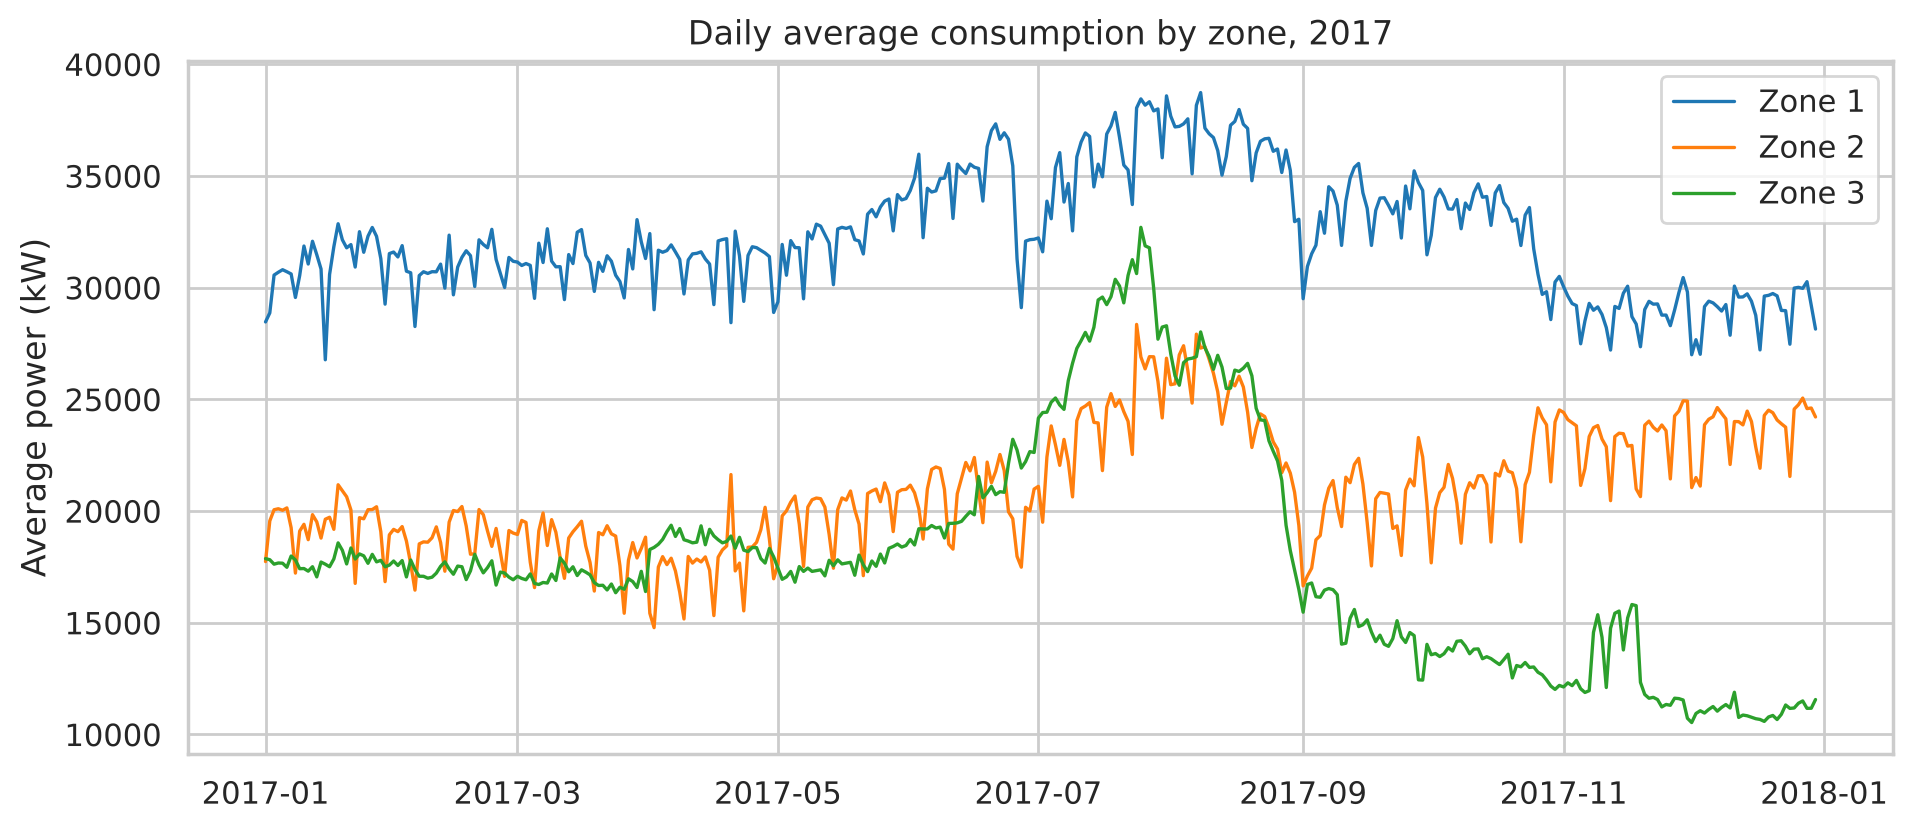

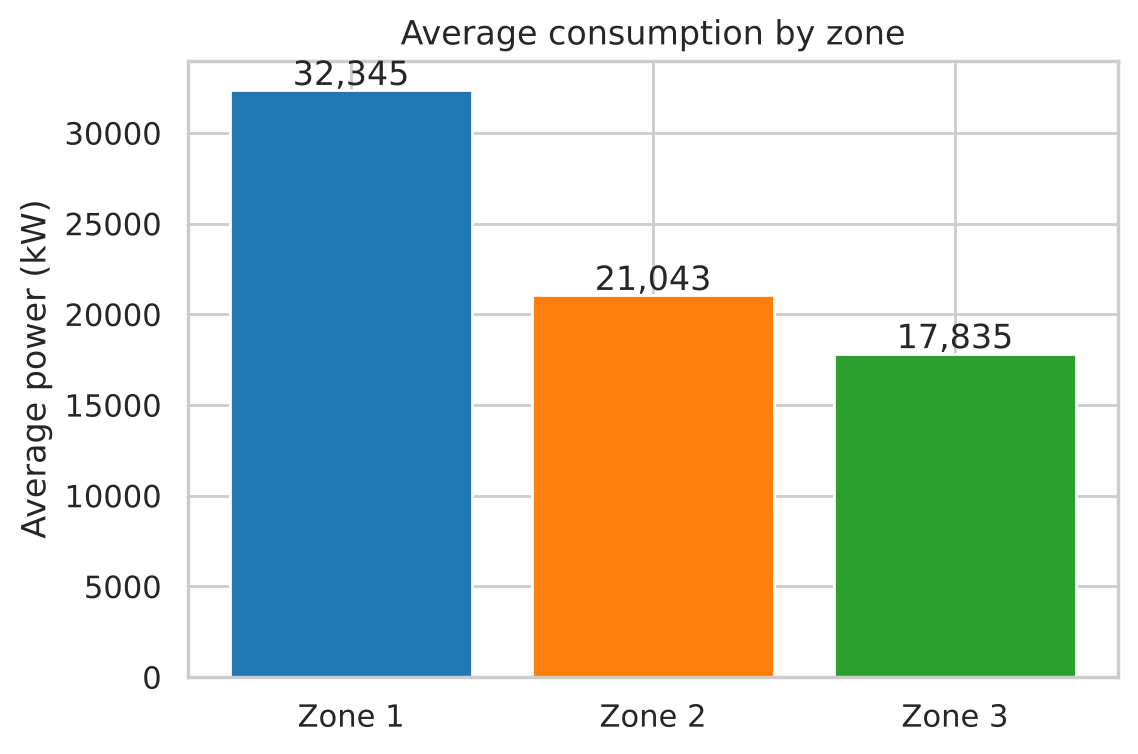

In [17]:
colors={'Zone 1':'#1f77b4','Zone 2':'#ff7f0e','Zone 3':'#2ca02c'}
# 1. Trend over time (daily average) - Matplotlib
fig,ax=plt.subplots(figsize=(11,4.5))
for z in ZONES: ax.plot(daily.index,daily[z],label=ZN[z],color=colors[ZN[z]],lw=1.2)
ax.set_title('Daily average consumption by zone, 2017'); ax.set_ylabel('Average power (kW)'); ax.set_xlabel(''); ax.legend(); save(fig,'01_daily_trend')
# 2. Average by zone - Matplotlib
fig,ax=plt.subplots(figsize=(6,4)); bars=ax.bar([ZN[z] for z in ZONES],avg.values,color=list(colors.values()))
for b,v in zip(bars,avg.values): ax.text(b.get_x()+b.get_width()/2,v+300,f'{v:,.0f}',ha='center')
ax.set_title('Average consumption by zone'); ax.set_ylabel('Average power (kW)'); save(fig,'02_average_by_zone')

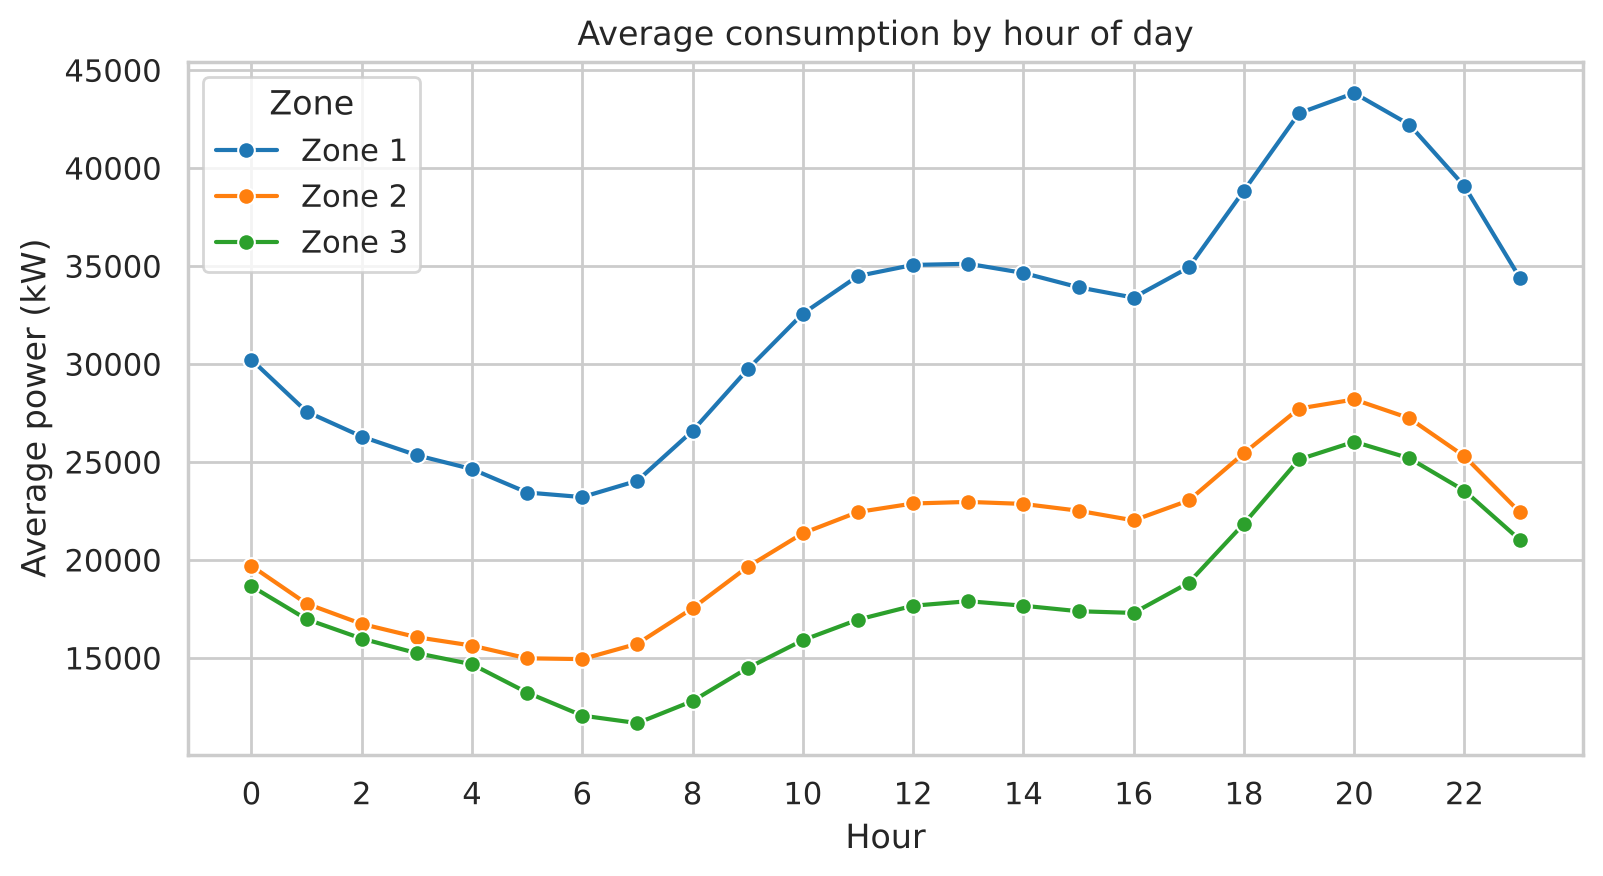

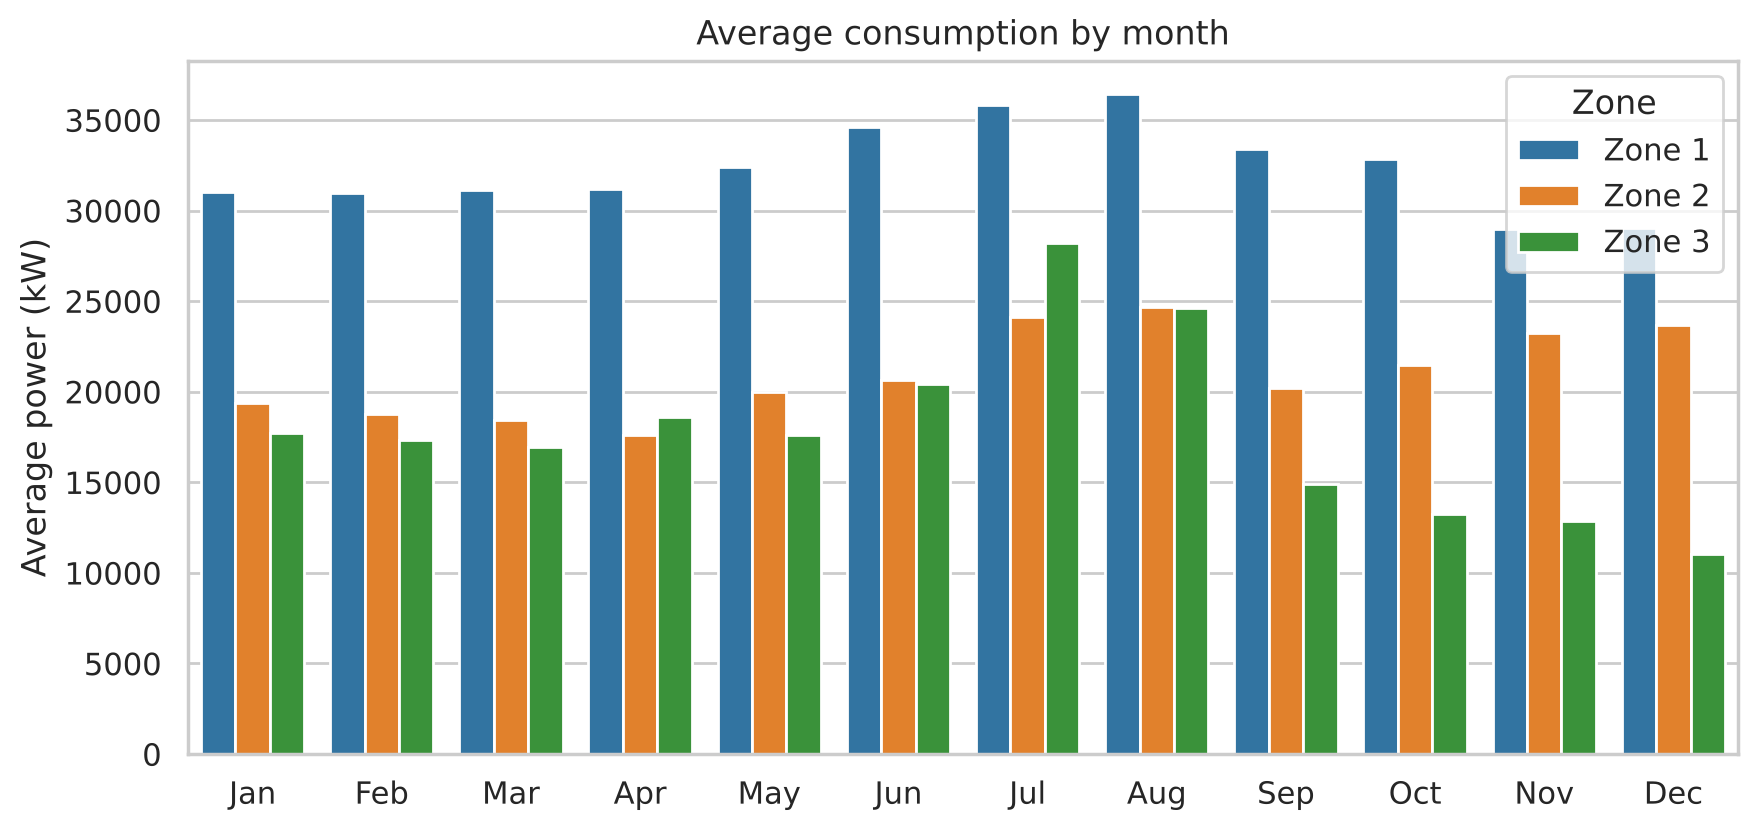

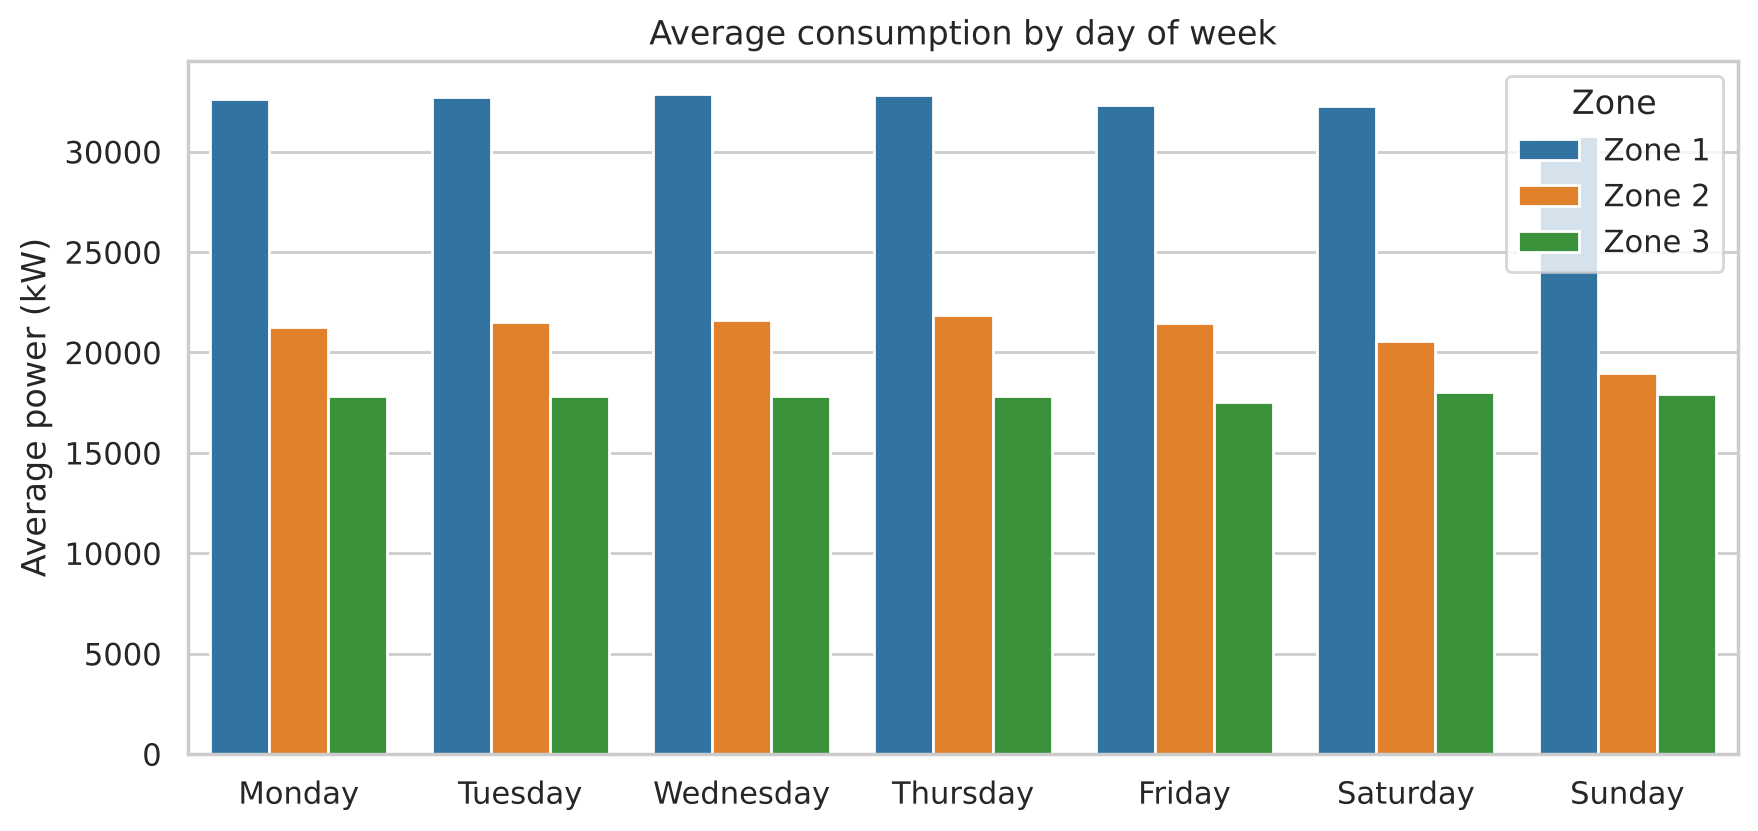

In [18]:
# 3. Hourly patterns - Seaborn
hl=hourly[['Zone 1','Zone 2','Zone 3']].reset_index().melt('Hour',var_name='Zone',value_name='kW')
fig,ax=plt.subplots(figsize=(9,4.5)); sns.lineplot(data=hl,x='Hour',y='kW',hue='Zone',palette=colors,marker='o',ax=ax)
ax.set_xticks(range(0,24,2)); ax.set_title('Average consumption by hour of day'); ax.set_ylabel('Average power (kW)'); save(fig,'03_hourly_pattern')
# 4. Monthly patterns - Seaborn
ml=mon[['Zone 1','Zone 2','Zone 3']].reset_index().melt('MonthName',var_name='Zone',value_name='kW')
fig,ax=plt.subplots(figsize=(10,4.5)); sns.barplot(data=ml,x='MonthName',y='kW',hue='Zone',palette=colors,ax=ax)
ax.set_title('Average consumption by month'); ax.set_xlabel(''); ax.set_ylabel('Average power (kW)'); save(fig,'04_monthly_pattern')
# 5. Day-of-week - Seaborn
dl=dow[['Zone 1','Zone 2','Zone 3']].reset_index().melt('DayOfWeek',var_name='Zone',value_name='kW')
fig,ax=plt.subplots(figsize=(10,4.5)); sns.barplot(data=dl,x='DayOfWeek',y='kW',hue='Zone',palette=colors,ax=ax)
ax.set_title('Average consumption by day of week'); ax.set_xlabel(''); ax.set_ylabel('Average power (kW)'); save(fig,'05_day_of_week')

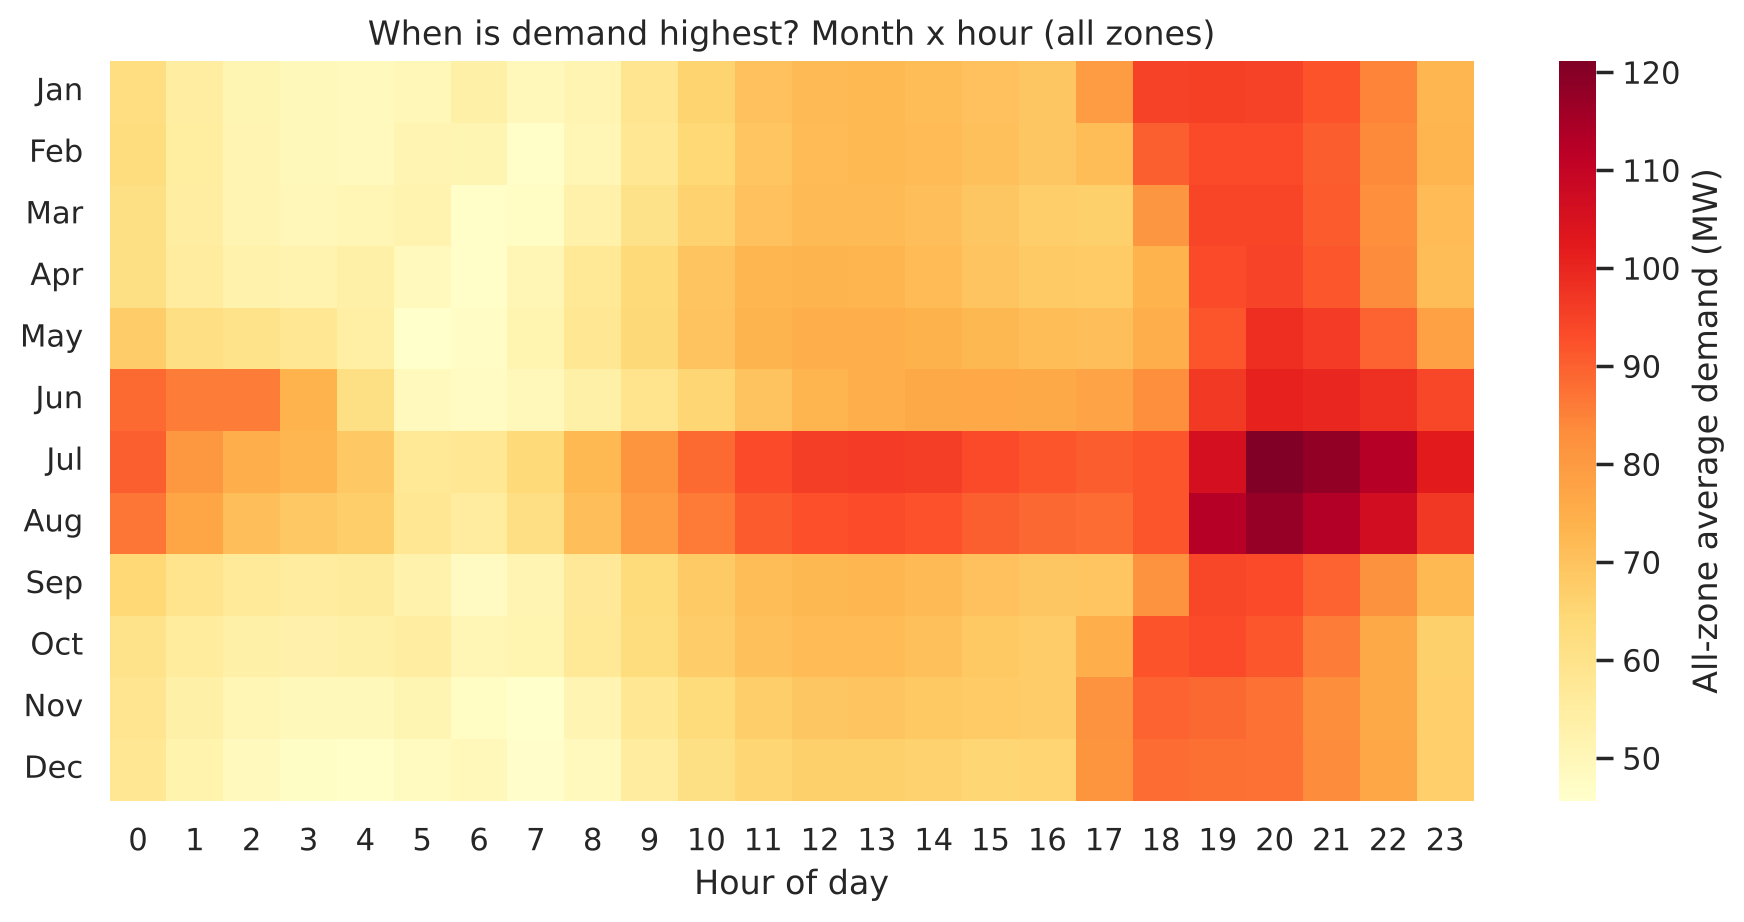

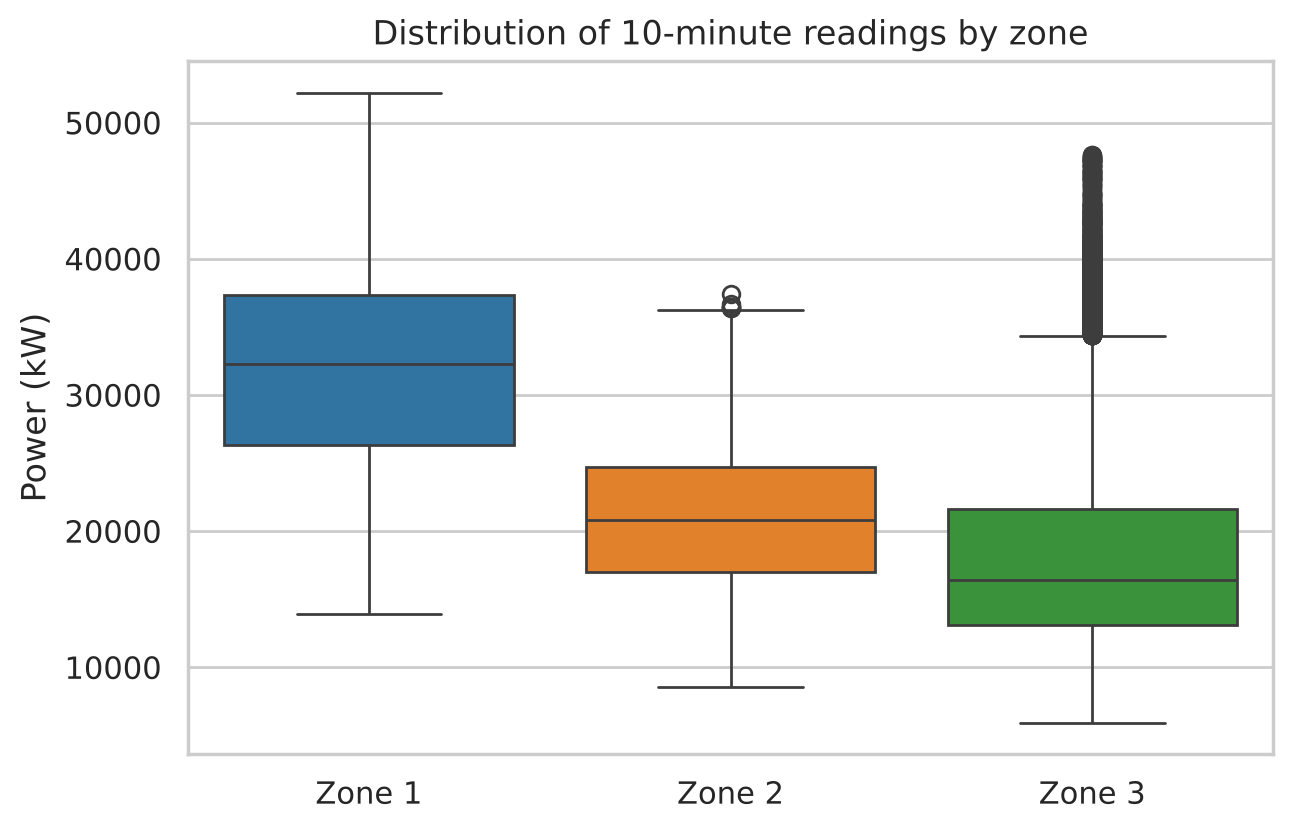

In [19]:
# 6. Hour x month heatmap of total demand - Seaborn
hm=df.pivot_table(index='MonthName',columns='Hour',values='Total_kW',aggfunc='mean',observed=True)
fig,ax=plt.subplots(figsize=(11,4.8)); sns.heatmap(hm/1000,cmap='YlOrRd',cbar_kws={'label':'All-zone average demand (MW)'},ax=ax)
ax.set_title('When is demand highest? Month x hour (all zones)'); ax.set_xlabel('Hour of day'); ax.set_ylabel(''); plt.setp(ax.get_yticklabels(), rotation=0); save(fig,'06_month_hour_heatmap')
# 7. Zone comparison - Seaborn boxplot
zl=df[ZONES].rename(columns=ZN).melt(var_name='Zone',value_name='kW')
fig,ax=plt.subplots(figsize=(7,4.5)); sns.boxplot(data=zl,x='Zone',y='kW',palette=colors,ax=ax); ax.set_title('Distribution of 10-minute readings by zone'); ax.set_ylabel('Power (kW)'); ax.set_xlabel(''); save(fig,'07_zone_boxplot')

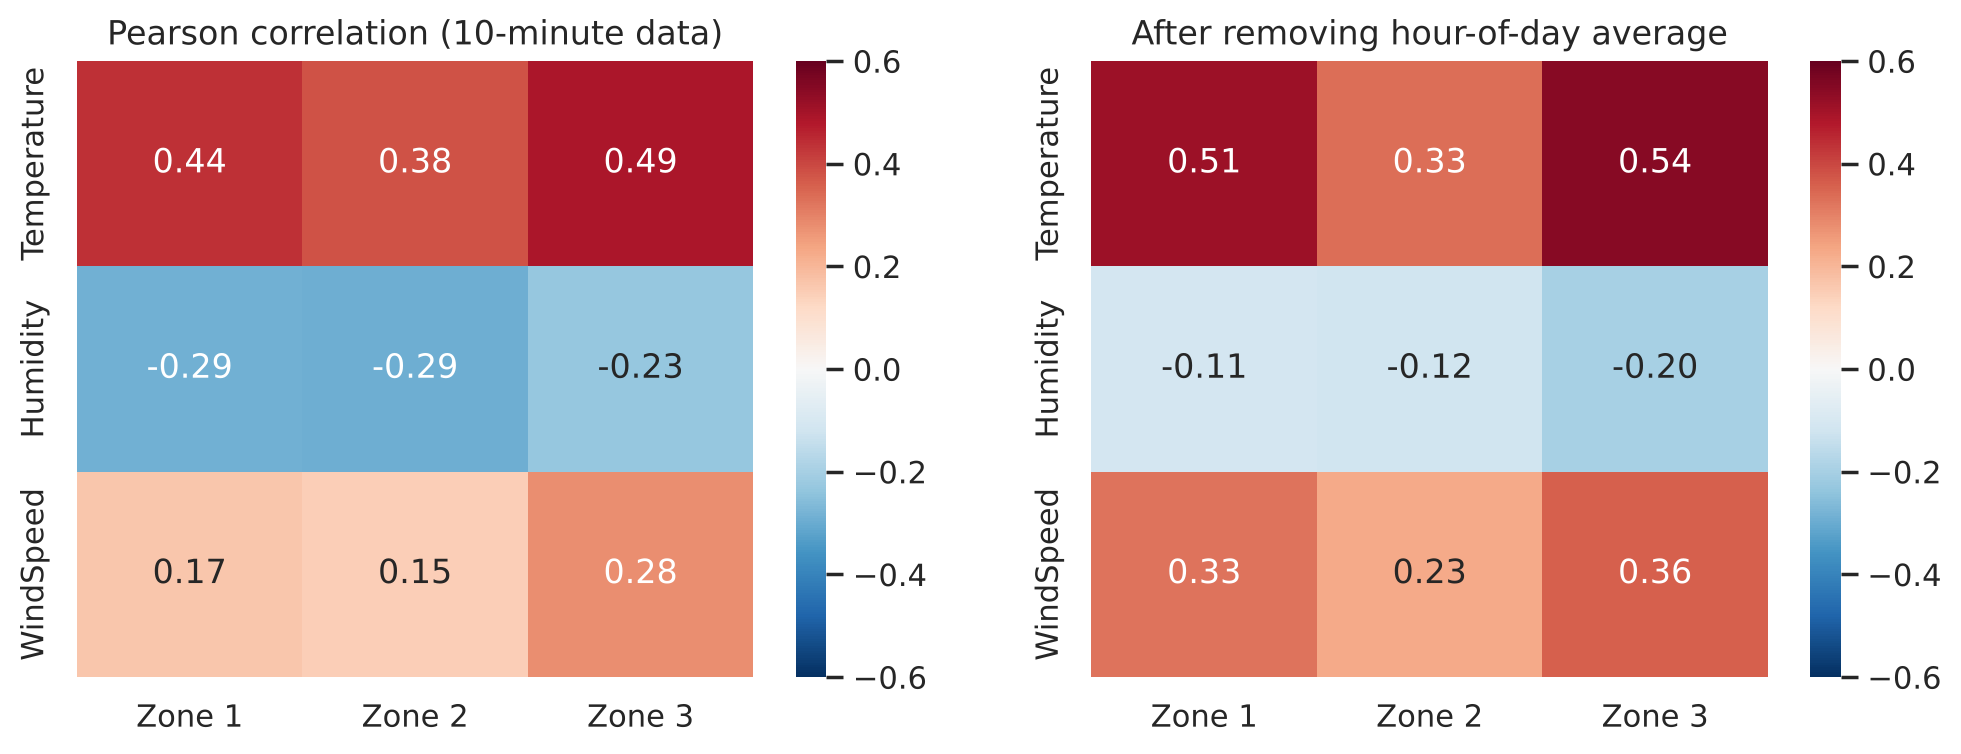

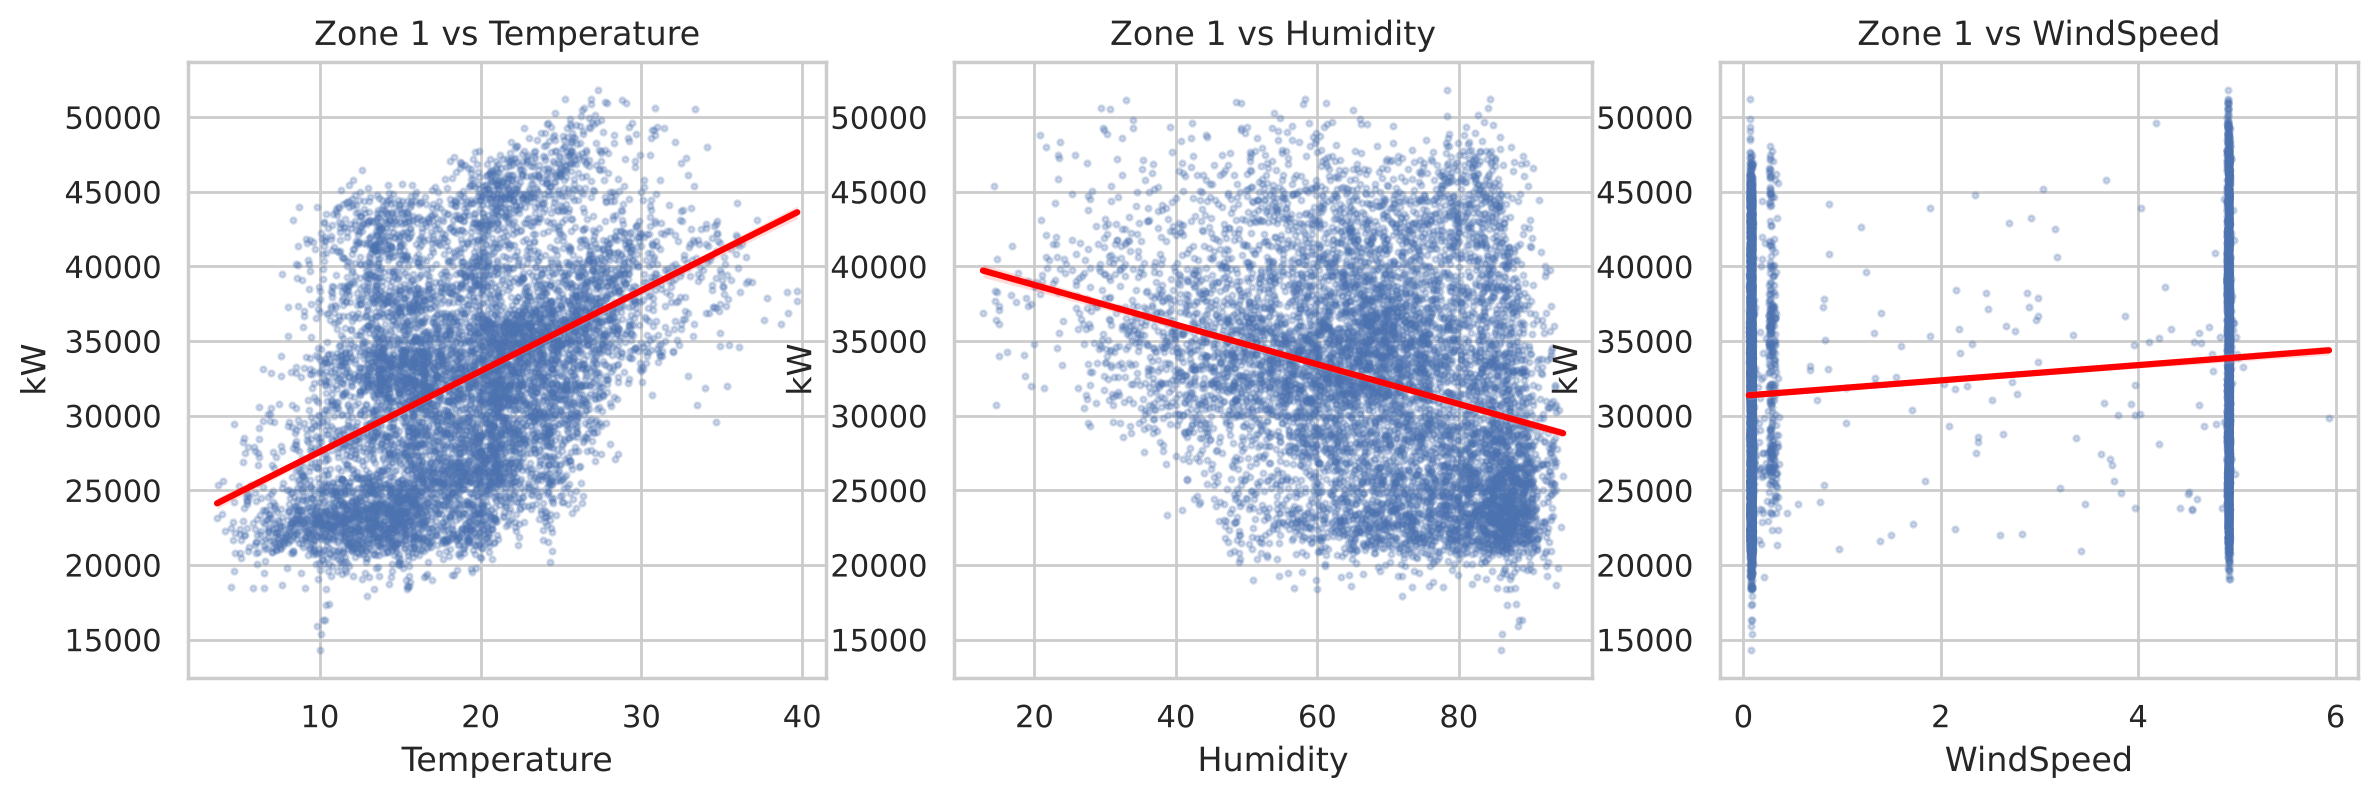

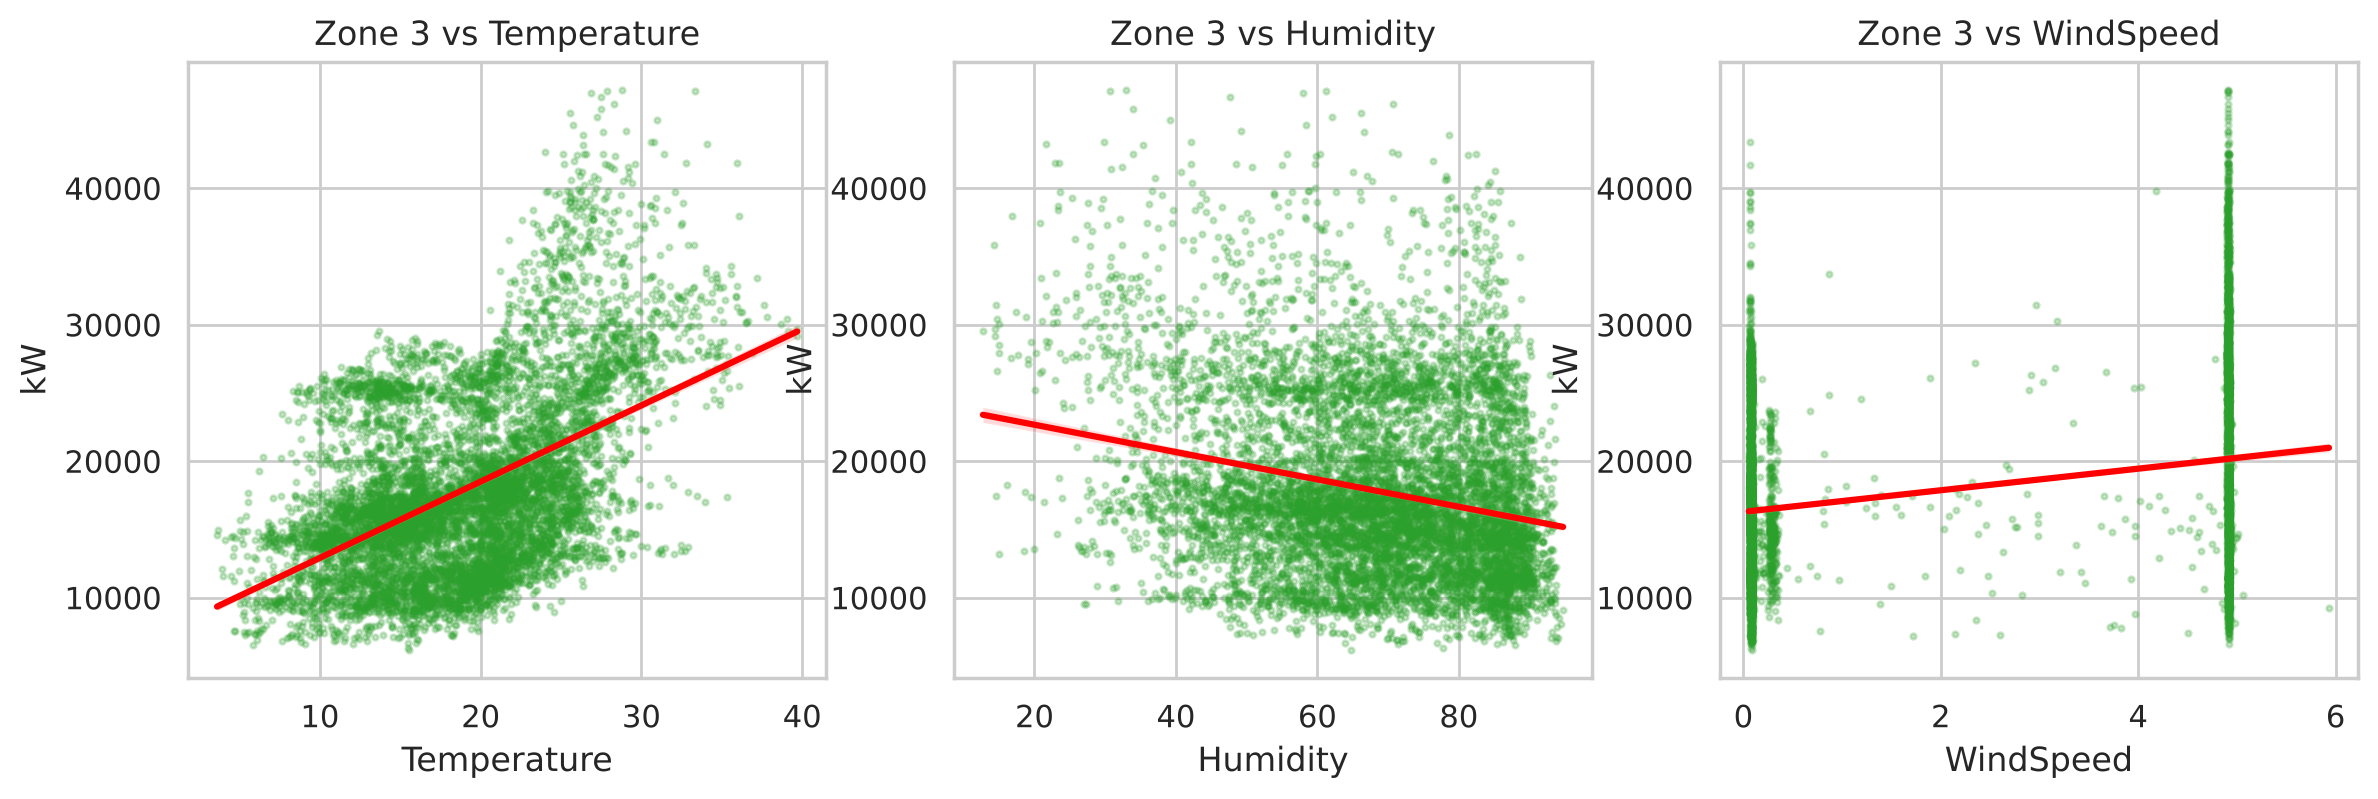

In [20]:
# 8. Environmental relationships - correlation heatmap + scatter on hourly averages
fig,axs=plt.subplots(1,2,figsize=(12,4)); 
sns.heatmap(p,annot=True,fmt='.2f',cmap='RdBu_r',vmin=-.6,vmax=.6,ax=axs[0]); axs[0].set_title('Pearson correlation (10-minute data)')
sns.heatmap(pa,annot=True,fmt='.2f',cmap='RdBu_r',vmin=-.6,vmax=.6,ax=axs[1]); axs[1].set_title('After removing hour-of-day average')
save(fig,'08_correlation_heatmaps')
hr=df.set_index('Datetime')[ENV+ZONES].resample('h').mean().dropna().reset_index()
fig,axs=plt.subplots(1,3,figsize=(14,4))
for a,e in zip(axs,ENV):
    sns.regplot(data=hr,x=e,y=ZONES[0],scatter_kws={'s':4,'alpha':.25},line_kws={'color':'red'},ax=a); a.set_title(f'Zone 1 vs {e}'); a.set_ylabel('kW')
save(fig,'09_env_scatter_zone1')
fig,axs=plt.subplots(1,3,figsize=(14,4))
for a,e in zip(axs,ENV):
    sns.regplot(data=hr,x=e,y=ZONES[2],scatter_kws={'s':4,'alpha':.25,'color':'#2ca02c'},line_kws={'color':'red'},ax=a); a.set_title(f'Zone 3 vs {e}'); a.set_ylabel('kW')
save(fig,'10_env_scatter_zone3')

In [21]:
# Interactive Plotly charts (saved as standalone HTML files; not a dashboard)
dd_=daily.rename(columns=ZN).reset_index().rename(columns={'index':'Date'}); dd_.columns=['Date','Zone 1','Zone 2','Zone 3','Total_kW']
f1=px.line(dd_,x='Date',y=['Zone 1','Zone 2','Zone 3'],title='Daily average consumption by zone (kW) – interactive',labels={'value':'kW','variable':'Zone'}); f1.write_html(f'{INTER}/daily_trend.html'); f1.show()
hp=hourly[['Zone 1','Zone 2','Zone 3']].reset_index()
f2=px.line(hp,x='Hour',y=['Zone 1','Zone 2','Zone 3'],markers=True,title='Hourly profile by zone (kW) – interactive',labels={'value':'kW','variable':'Zone'}); f2.write_html(f'{INTER}/hourly_profile.html'); f2.show()
mp=mon[['Zone 1','Zone 2','Zone 3']].reset_index()
f3=px.bar(mp,x='MonthName',y=['Zone 1','Zone 2','Zone 3'],barmode='group',title='Monthly average consumption by zone (kW) – interactive',labels={'value':'kW','variable':'Zone','MonthName':'Month'}); f3.write_html(f'{INTER}/monthly_pattern.html'); f3.show()

In [22]:
dw=dow[['Zone 1','Zone 2','Zone 3']].reset_index()
f4=px.bar(dw,x='DayOfWeek',y=['Zone 1','Zone 2','Zone 3'],barmode='group',title='Average consumption by day of week (kW) – interactive',labels={'value':'kW','variable':'Zone','DayOfWeek':''}); f4.write_html(f'{INTER}/day_of_week.html'); f4.show()
dly2=dly.reset_index().rename(columns={'Date':'Date'})
f5=px.scatter(dly2,x='Temperature',y=ZONES[0],color='Humidity',hover_data=['Date','WindSpeed'],trendline='ols',title='Zone 1 vs temperature (daily averages) – interactive',labels={ZONES[0]:'Zone 1 (kW)'}); f5.write_html(f'{INTER}/temperature_vs_zone1.html'); f5.show()
f6=px.scatter(dly2,x='Temperature',y=ZONES[2],color='Humidity',hover_data=['Date','WindSpeed'],trendline='ols',title='Zone 3 vs temperature (daily averages) – interactive',labels={ZONES[2]:'Zone 3 (kW)'}); f6.write_html(f'{INTER}/temperature_vs_zone3.html'); f6.show()
f7=px.imshow((hm/1000).round(1),aspect='auto',color_continuous_scale='YlOrRd',labels=dict(x='Hour',y='Month',color='MW'),title='All-zone demand: month x hour (MW) – interactive'); f7.write_html(f'{INTER}/month_hour_heatmap.html'); f7.show()

## Task 6 – Business insights and recommendations

In [23]:
A=R['avg']; hp_=R['hour_peak']; mp_=R['month_peak']
display(Markdown(f'''
### Key findings
1. **Zone 1 is the largest, Zone 3 the smallest on average.** Average demand is {A['Zone 1']:,.0f} kW (Zone 1), {A['Zone 2']:,.0f} kW (Zone 2) and {A['Zone 3']:,.0f} kW (Zone 3), i.e. {R['share']['Zone 1']:.0f}% / {R['share']['Zone 2']:.0f}% / {R['share']['Zone 3']:.0f}% of total average demand.
2. **A strong daily cycle drives demand.** The all-zone peak is at {hp_['All zones']}:00 and the lowest point at {R['hour_low']['All zones']}:00. Evening demand (19–21h) is about {R['evening_vs_morning']:.1f}x the pre-dawn level (4–6h).
3. **Summer is the high season.** The all-zone peak month is {mp_['All zones']}. Zone 3 is the most seasonal: July demand is about {R['z3_jul_vs_dec']:.1f}x December.
4. **Zones do not share the same seasonal shape.** Zone 3 peaks in July and falls sharply from September; Zone 2 is higher in the cooler months (Nov–Dec) than in spring.
5. **Day of week matters little, but Sunday is lower in Zone 1.** The weekday spread of all-zone demand is only {R['dow_range_pct']:.1f}% of the mean; weekends average {R['weekend_pct']:.1f}% versus weekdays.
6. **Temperature is the environmental variable most associated with demand** (moderate positive), humidity is weakly negative, wind speed weak. The temperature link stays similar after removing the daily cycle, but it still overlaps with season, so it is association, not causation.
7. **Zone 3 has the most extreme peaks** (the highest reading is {R['peak']['Zone 3'][0]:,.0f} kW, {R['peak']['Zone 3'][1]}), concentrated on summer evenings, and the highest variability relative to its mean.

### What this means for an energy management organisation
- Capacity and staffing pressure is concentrated in a **narrow evening window in summer**, and most strongly in Zone 3.
- Because the daily shape is stable, **demand is predictable by hour and month**, which is valuable for planning.
- Weather (especially temperature) helps explain demand, but time of day and month remain the dominant planning inputs.

### Recommendations
1. **Plan evening capacity by zone and season**: prioritise reserve capacity for Zone 3 in July–August evenings and Zone 1 in the 19:00–21:00 window year-round.
2. **Use demand-response / load-shifting for the evening peak**: tariffs or incentives aimed at moving flexible load out of 19:00–21:00 in summer would reduce peak stress.
3. **Schedule maintenance and low-risk works in the low-demand window** (early morning, roughly 04:00–07:00, and cooler months) to limit service risk.
4. **Build forecasts on time-of-day, month and zone, adding temperature as a secondary driver**, rather than relying on weather alone.
5. **Collect more data**: at least 2–3 years (to separate seasonality from one-off events), the true unit definition, and a correct definition for the diffuse-flow variables.
'''))


### Key findings
1. **Zone 1 is the largest, Zone 3 the smallest on average.** Average demand is 32,345 kW (Zone 1), 21,043 kW (Zone 2) and 17,835 kW (Zone 3), i.e. 45% / 30% / 25% of total average demand.
2. **A strong daily cycle drives demand.** The all-zone peak is at 20:00 and the lowest point at 6:00. Evening demand (19–21h) is about 1.8x the pre-dawn level (4–6h).
3. **Summer is the high season.** The all-zone peak month is Jul. Zone 3 is the most seasonal: July demand is about 2.6x December.
4. **Zones do not share the same seasonal shape.** Zone 3 peaks in July and falls sharply from September; Zone 2 is higher in the cooler months (Nov–Dec) than in spring.
5. **Day of week matters little, but Sunday is lower in Zone 1.** The weekday spread of all-zone demand is only 6.8% of the mean; weekends average -3.8% versus weekdays.
6. **Temperature is the environmental variable most associated with demand** (moderate positive), humidity is weakly negative, wind speed weak. The temperature link stays similar after removing the daily cycle, but it still overlaps with season, so it is association, not causation.
7. **Zone 3 has the most extreme peaks** (the highest reading is 47,598 kW, 2017-07-24 20:10:00), concentrated on summer evenings, and the highest variability relative to its mean.

### What this means for an energy management organisation
- Capacity and staffing pressure is concentrated in a **narrow evening window in summer**, and most strongly in Zone 3.
- Because the daily shape is stable, **demand is predictable by hour and month**, which is valuable for planning.
- Weather (especially temperature) helps explain demand, but time of day and month remain the dominant planning inputs.

### Recommendations
1. **Plan evening capacity by zone and season**: prioritise reserve capacity for Zone 3 in July–August evenings and Zone 1 in the 19:00–21:00 window year-round.
2. **Use demand-response / load-shifting for the evening peak**: tariffs or incentives aimed at moving flexible load out of 19:00–21:00 in summer would reduce peak stress.
3. **Schedule maintenance and low-risk works in the low-demand window** (early morning, roughly 04:00–07:00, and cooler months) to limit service risk.
4. **Build forecasts on time-of-day, month and zone, adding temperature as a secondary driver**, rather than relying on weather alone.
5. **Collect more data**: at least 2–3 years (to separate seasonality from one-off events), the true unit definition, and a correct definition for the diffuse-flow variables.


### Limitations
- One year of data (364 days): seasonality cannot be separated from one-off events, and no year-on-year comparison is possible.
- Unit and diffuse-flow definitions in the dictionary are doubtful; treated here as kW and solar-radiation-like variables.
- Correlations are associations only; temperature, humidity, time of day and season are entangled.
- Zones are not geographically described, so zone differences cannot be explained by land use or customer mix.

In [24]:
json.dump(R, open('results.json','w'), indent=1, default=float); print('results.json saved')

results.json saved
